In [161]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.dummy import DummyClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#Task 1. Load and Inspect the Employee Records
#a) Load the workbook using pd.read excel(). Display the first five rows and the shape of the full dataset.
current_dir = Path(os.getcwd())
file_path = current_dir.parent.parent / "data" / "WA_Fn-UseC_-HR-Employee-Attrition_16112026.csv"
employeeDataExtract = pd.read_csv(file_path)

#Display the data types and missing-value counts for the seven selected inputs and the target. Report how many target labels are missing or outside the expected values Yes and No. 
#Exclude those rows before proceeding.


print("Data types:")
employeeData = employeeDataExtract.convert_dtypes()
print(employeeData.head())
print(employeeData.dtypes)

print("\nMissing values:")
print(employeeData.isnull().sum())

features = [
    'Age',
    'DistanceFromHome',
    'MonthlyIncome',
    'YearsAtCompany',
    'JobSatisfaction',
    'Department',
    'OverTime'
]

target = 'Attrition'

valid_labels = ['Yes', 'No']

invalid_target = ~employeeData["Attrition"].isin(valid_labels)

print("\nMissing or invalid target labels:")
print(invalid_target.sum())

X = employeeData[features]
y = employeeData[target]

Data types:
   Age Attrition     BusinessTravel  DailyRate              Department  \
0   41       Yes      Travel_Rarely       1102                   Sales   
1   49        No  Travel_Frequently        279  Research & Development   
2   37       Yes      Travel_Rarely       1373  Research & Development   
3   33        No  Travel_Frequently       1392  Research & Development   
4   27        No      Travel_Rarely        591  Research & Development   

   DistanceFromHome  Education EducationField  EmployeeCount  EmployeeNumber  \
0                 1          2  Life Sciences              1               1   
1                 8          1  Life Sciences              1               2   
2                 2          2          Other              1               4   
3                 3          4  Life Sciences              1               5   
4                 2          1        Medical              1               7   

   ...  RelationshipSatisfaction StandardHours  StockOptionLev

,Count,Percentage
Attrition,,
No,1233,83.877551
Yes,237,16.122449


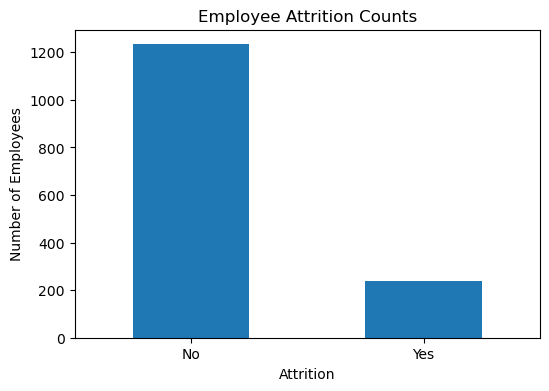

In [162]:
#Task 2: Determine How Common Attrition Is
#2(a) Report the number and percentage of employees in each attrition class. Plot the class counts as a bar chart.
attrition_counts = employeeData['Attrition'].value_counts()
attrition_percentages = (employeeData['Attrition'].value_counts(normalize=True) * 100)

attrition_summary = pd.DataFrame({
    'Count': attrition_counts,
    'Percentage': attrition_percentages
})

display(attrition_summary)

plt.figure(figsize=(6, 4))

attrition_counts.plot(kind='bar')

plt.title('Employee Attrition Counts')
plt.xlabel('Attrition')
plt.ylabel('Number of Employees')
plt.xticks(rotation=0)

plt.show()

In [163]:
#2(b) Attrition percentage based on overtime
overtime_summary = employeeData.groupby('OverTime')['Attrition'].agg(
    Total='count',
    Employees_Left=lambda x: (x == 'Yes').sum()
)

overtime_summary['Attrition_Percentage'] = (
    overtime_summary['Employees_Left'] /
    overtime_summary['Total'] * 100
)

display(overtime_summary)

,Total,Employees_Left,Attrition_Percentage
OverTime,,,
No,1054,110,10.436433
Yes,416,127,30.528846


In [164]:
#c) Which overtime group had the higher observed attrition rate? If both groups are present,
#give the difference in percentage points. Explain what this comparison tells you about the
#employees in the sheet.
if len(overtime_summary) == 2:
    difference = abs(
        overtime_summary.loc['Yes', 'Attrition_Percentage'] -
        overtime_summary.loc['No', 'Attrition_Percentage']
    )

    print("Difference:", round(difference, 2), "percentage points")

Difference: 20.09 percentage points


In [165]:
#Task 3. Prepare the Training and Test Sets
#a) Create X using the seven input columns. Create y by encoding Attrition as 1 for Yes and 0 for No.
X = employeeData[features].copy()

print("Input features:")
display(X.head())

print("\nTarget values:")
print(y.value_counts())

Input features:


,Age,DistanceFromHome,MonthlyIncome,YearsAtCompany,JobSatisfaction,Department,OverTime
0,41,1,5993,6,4,Sales,Yes
1,49,8,5130,10,2,Research & Development,No
2,37,2,2090,0,3,Research & Development,Yes
3,33,3,2909,8,3,Research & Development,Yes
4,27,2,3468,2,2,Research & Development,No



Target values:
Attrition
No     1233
Yes     237
Name: count, dtype: Int64


In [176]:
#b) Use train test split() to create an 80% training set and a 20% test set. Use stratify=y.
y = employeeData['Attrition'].map({
    'Yes': 1,
    'No': 0
})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

In [177]:
#c) Report the number of records and the percentage of employees who left in each split. What does stratification help preserve?
train_count = 0
for att in y_train:
    if att == 1:
        train_count += 1

test_count = 0
for att in y_test:
    if att == 1:
        test_count += 1 
print("Training attrition percentage:", round(train_count/len(y_train) * 100, 2), "%")
print("Testing attrition percentage:", round(test_count/len(y_test) * 100, 2), "%")

Training attrition percentage: 16.16 %
Testing attrition percentage: 15.99 %


In [178]:
#Task 4. Prepare the Inputs for the Neural Network
#a) Use StandardScaler for the numerical inputs. If numerical values are missing, fill them
#with the training median for the corresponding column before scaling.
# Numerical preprocessing
numerical_features = [
    'Age',
    'DistanceFromHome',
    'MonthlyIncome',
    'YearsAtCompany',
    'JobSatisfaction'
]

categorical_features = [
    'Department',
    'OverTime'
]


# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [179]:
#Task 5. Train a Baseline and a Neural Network
#a) Train a baseline with DummyClassifier(strategy="most frequent"). This model predicts the most frequent class in the training set.

baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
baseline_predictions = baseline.predict(X_test)

print("Baseline model trained successfully.")

Baseline model trained successfully.


In [180]:
#b) Build a Pipeline that combines the preprocessor from Task 4 with an MLPClassifier. Use the following settings throughout the assignment.
#The neural network contains:

    
neural_network = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', MLPClassifier(
        hidden_layer_sizes=(100,),
        max_iter=500,
        random_state=42
    ))
])

neural_network.fit(X_train, y_train)

nn_predictions = neural_network.predict(X_test)

print("Neural network trained successfully.")

Neural network trained successfully.


D:\anaconda\envs\ai_env\lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (500) reached and the optimization hasn't converged yet.
  warnings.warn(


In [181]:
#Task 6: Decide Which Model Better Detects Attrition
#6(a) Create a results table with test accuracy, precision, recall, and F1-score for each model. Use Attrition = Yes as the positive class. Use zero division=0 for precision, recall, nd F1
results = pd.DataFrame({
    'Model': ['Baseline', 'Neural Network'],
    'Accuracy': [
        accuracy_score(y_test, baseline_predictions),
        accuracy_score(y_test, nn_predictions)
    ],
    'Precision': [
        precision_score(y_test, baseline_predictions, zero_division=0),
        precision_score(y_test, nn_predictions, zero_division=0)
    ],
    'Recall': [
        recall_score(y_test, baseline_predictions, zero_division=0),
        recall_score(y_test, nn_predictions, zero_division=0)
    ],
    'F1 Score': [
        f1_score(y_test, baseline_predictions, zero_division=0),
        f1_score(y_test, nn_predictions, zero_division=0)
    ]
})

display(results.round(3))

,Model,Accuracy,Precision,Recall,F1 Score
0,Baseline,0.840,0.000,0.000,0.0
1,Neural Network,0.857,0.609,0.298,0.4


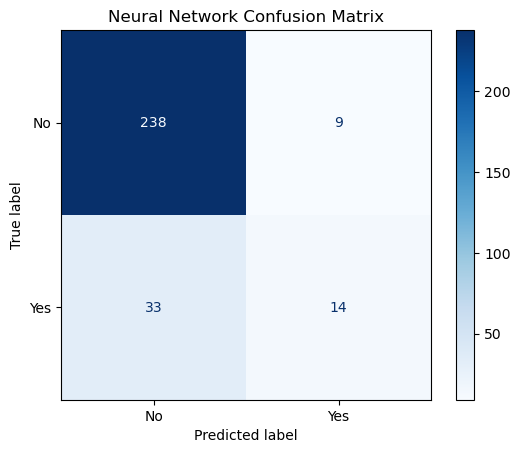

True Positives: 14
False Positives: 9
True Negatives: 238
False Negatives: 33


In [182]:
#b) Plot the neural network’s test confusion matrix. Report the true positives, false positives, true negatives, and false negatives in the context of employee attrition.
cm = confusion_matrix(y_test, nn_predictions, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues')

plt.title('Neural Network Confusion Matrix')
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Positives:", tp)
print("False Positives:", fp)
print("True Negatives:", tn)
print("False Negatives:", fn)
#True Positive (TP): Employees who actually left and were correctly predicted to leave.
#False Positive (FP): Employees who stayed but were incorrectly predicted to leave.
#True Negative (TN): Employees who stayed and were correctly predicted to stay.
#False Negative (FN): Employees who actually left but were incorrectly predicted to stay.

In [183]:
#c) Of the employees who actually left, how many did the model correctly identify and how many did it miss? Verify the recall using the counts in your confusion matrix.
actual_departures = tp + fn

print("Actual departures:", actual_departures)
print("Correctly identified departures:", tp)
print("Missed departures:", fn)

if actual_departures > 0:
    calculated_recall = tp / actual_departures
else:
    calculated_recall = 0

print("Recall:", round(calculated_recall, 3))

Actual departures: 47
Correctly identified departures: 14
Missed departures: 33
Recall: 0.298


In [184]:
#Task 7. Examine Individual Predictions
#a) Use predict proba() to obtain the model’s estimated probability of attrition for each test record.
nn_probabilities = neural_network.predict_proba(X_test)[:, 1]

print("First 10 attrition probabilities:")
print(nn_probabilities[:10])

First 10 attrition probabilities:
[0.65398448 0.05723086 0.05309971 0.00685074 0.26475607 0.0780659
 0.07212983 0.0090859  0.03689345 0.59771968]


In [185]:
#b) Display up to three false negatives and three false positives, when available. Show the actual label, predicted label, estimated probability of attrition, and two or three input
#values.
prediction_results = X_test.copy()

prediction_results['Actual'] = y_test
prediction_results['Predicted'] = nn_predictions
prediction_results['Attrition_Probability'] = nn_probabilities

# False negatives
false_negatives = prediction_results[
    (prediction_results['Actual'] == 1) &
    (prediction_results['Predicted'] == 0)
]

# False positives
false_positives = prediction_results[
    (prediction_results['Actual'] == 0) &
    (prediction_results['Predicted'] == 1)
]

columns_to_display = [
    'Age',
    'MonthlyIncome',
    'OverTime',
    'Actual',
    'Predicted',
    'Attrition_Probability'
]

print("False Negatives:")
display(false_negatives[columns_to_display].head(3))

print("False Positives:")
display(false_positives[columns_to_display].head(3))

False Negatives:


,Age,MonthlyIncome,OverTime,Actual,Predicted,Attrition_Probability
69,36,3388,Yes,1,0,0.264756
645,29,2800,Yes,1,0,0.412179
985,31,6179,Yes,1,0,0.162714


False Positives:


,Age,MonthlyIncome,OverTime,Actual,Predicted,Attrition_Probability
1061,24,2033,No,0,1,0.653984
1311,18,1514,No,0,1,0.597720
474,24,2725,Yes,0,1,0.511994


In [186]:
#c) Select one error from your table and explain what the model predicted and what actually happened. If there are no errors, describe two correct predictions instead.
if len(false_negatives) > 0:
    example = false_negatives.iloc[0]

    print("Example: False Negative")
    print("Actual Attrition:", example['Actual'])
    print("Predicted Attrition:", example['Predicted'])
    print("Estimated Probability:",
          round(example['Attrition_Probability'], 3))

    print("Explanation: The employee actually left the company,")
    print("but the neural network predicted that the employee would stay.")

elif len(false_positives) > 0:
    example = false_positives.iloc[0]

    print("Example: False Positive")
    print("Actual Attrition:", example['Actual'])
    print("Predicted Attrition:", example['Predicted'])
    print("Estimated Probability:",
          round(example['Attrition_Probability'], 3))

    print("Explanation: The employee actually stayed,")
    print("but the neural network predicted that the employee would leave.")

else:
    print("No prediction errors were found.")

Example: False Negative
Actual Attrition: 1
Predicted Attrition: 0
Estimated Probability: 0.265
Explanation: The employee actually left the company,
but the neural network predicted that the employee would stay.


In [187]:
#Task 8. Propose an Action for the HR Analytics Team
# a) Write a short recommendation for the HR analytics team. Include the observed attrition rate, the baseline and neural network recall, and the number of actual departures the neural network missed.
overall_attrition_rate = (df['Attrition'] == 'Yes').mean() * 100

baseline_recall = recall_score(
    y_test,
    baseline_predictions,
    zero_division=0
)

nn_recall = recall_score(
    y_test,
    nn_predictions,
    zero_division=0
)

print("Overall Attrition Rate:",
      round(overall_attrition_rate, 2), "%")

print("Baseline Recall:",
      round(baseline_recall, 3))

print("Neural Network Recall:",
      round(nn_recall, 3))

print("Actual departures missed by Neural Network:", fn)

Overall Attrition Rate: 16.12 %
Baseline Recall: 0.0
Neural Network Recall: 0.298
Actual departures missed by Neural Network: 33
